In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
print("✅ Libraries loaded!")

✅ Libraries loaded!


In [2]:
# Load full dataset
print("Loading full Rossmann dataset...")
df = pd.read_csv('C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/train_with_features.csv')
df['Date'] = pd.to_datetime(df['Date'])

# Filter open days only
df_open = df[df['Open'] == 1].copy()

print(f"✅ Data loaded!")
print(f"Total stores: {df_open['Store'].nunique()}")
print(f"Total records: {len(df_open):,}")
print(f"Date range: {df_open['Date'].min().date()} to {df_open['Date'].max().date()}")


Loading full Rossmann dataset...
✅ Data loaded!
Total stores: 1115
Total records: 844,392
Date range: 2013-01-01 to 2015-07-31


In [3]:
print("Calculating metrics for all stores...")

store_metrics = []

for store_id in df_open['Store'].unique()[:50]:  # Analyze first 50 stores for speed
    store_data = df_open[df_open['Store'] == store_id].sort_values('Date')
    
    if len(store_data) < 100:  # Skip stores with too little data
        continue
    
    sales = store_data['Sales'].values
    
    # Calculate metrics
    metrics = {
        'Store': store_id,
        'Records': len(store_data),
        'Mean_Sales': sales.mean(),
        'Std_Sales': sales.std(),
        'CV': (sales.std() / sales.mean()) * 100,  # Coefficient of Variation
        'Min_Sales': sales.min(),
        'Max_Sales': sales.max(),
        'Range': sales.max() - sales.min(),
        'Autocorr_Lag1': pd.Series(sales).autocorr(lag=1),  # Yesterday correlation
        'Autocorr_Lag7': pd.Series(sales).autocorr(lag=7),  # Last week correlation
    }
    
    store_metrics.append(metrics)
    
    if len(store_metrics) % 10 == 0:
        print(f"  Processed {len(store_metrics)} stores...")

store_metrics_df = pd.DataFrame(store_metrics)

print(f"\n✅ Analyzed {len(store_metrics_df)} stores!")
print("\nSample metrics:")
display(store_metrics_df.head(10))


Calculating metrics for all stores...
  Processed 10 stores...
  Processed 20 stores...
  Processed 30 stores...
  Processed 40 stores...
  Processed 50 stores...

✅ Analyzed 50 stores!

Sample metrics:


,Store,Records,Mean_Sales,Std_Sales,CV,Min_Sales,Max_Sales,Range,Autocorr_Lag1,Autocorr_Lag7
0,1,781,4759.096031,1011.458230,21.253159,2362,9528,7166,0.682691,-0.057120
1,2,784,4953.900510,1609.121894,32.481918,1919,10682,8763,0.289095,-0.242282
2,3,779,6942.568678,2191.975532,31.572976,2936,15689,12753,0.349731,-0.344369
3,4,784,9638.401786,1934.796773,20.073834,5869,17412,11543,0.621659,-0.112389
4,5,779,4676.274711,1764.611923,37.735420,1423,11692,10269,0.112693,-0.283292
5,6,780,5509.946154,1576.368668,28.609511,2355,11139,8784,0.293989,-0.070588
6,7,786,8817.050891,2447.060742,27.753733,3020,18413,15393,0.281562,-0.176150
7,8,784,5539.358418,1892.886204,34.171578,1725,10971,9246,0.273238,-0.199254
8,9,779,6562.337612,1627.608255,24.802263,2724,13457,10733,0.559828,-0.028920
9,10,784,5568.420918,1050.462195,18.864633,3481,9534,6053,0.363387,-0.206190


In [4]:
store_metrics_df['Complexity_Score'] = (
    store_metrics_df['CV'] * 0.4 +  # Volatility (40%)
    (1 - store_metrics_df['Autocorr_Lag1']) * 100 * 0.4 +  # Low autocorr (40%)
    store_metrics_df['Autocorr_Lag7'] * 100 * 0.2  # Seasonal pattern (20%)
)

# Sort by complexity
store_metrics_df = store_metrics_df.sort_values('Complexity_Score', ascending=False)

print("="*80)
print("STORE COMPLEXITY RANKING")
print("="*80)
print("Higher Complexity Score = More challenging = Better for ARIMA\n")
display(store_metrics_df[['Store', 'CV', 'Autocorr_Lag1', 'Autocorr_Lag7', 'Complexity_Score']].head(15))


STORE COMPLEXITY RANKING
Higher Complexity Score = More challenging = Better for ARIMA



,Store,CV,Autocorr_Lag1,Autocorr_Lag7,Complexity_Score
4,5,37.735420,0.112693,-0.283292,44.920593
27,28,40.591229,0.199685,-0.255770,43.133688
16,17,39.396433,0.212615,-0.308287,41.088242
13,14,26.843590,0.092687,-0.319638,40.637205
19,20,21.839306,0.147428,-0.168448,39.469644
7,8,34.171578,0.273238,-0.199254,38.754013
5,6,28.609511,0.293989,-0.070588,38.272499
17,18,27.167734,0.187441,-0.276979,37.829850
31,32,31.416426,0.209145,-0.326962,37.661552
1,2,32.481918,0.289095,-0.242282,36.583351


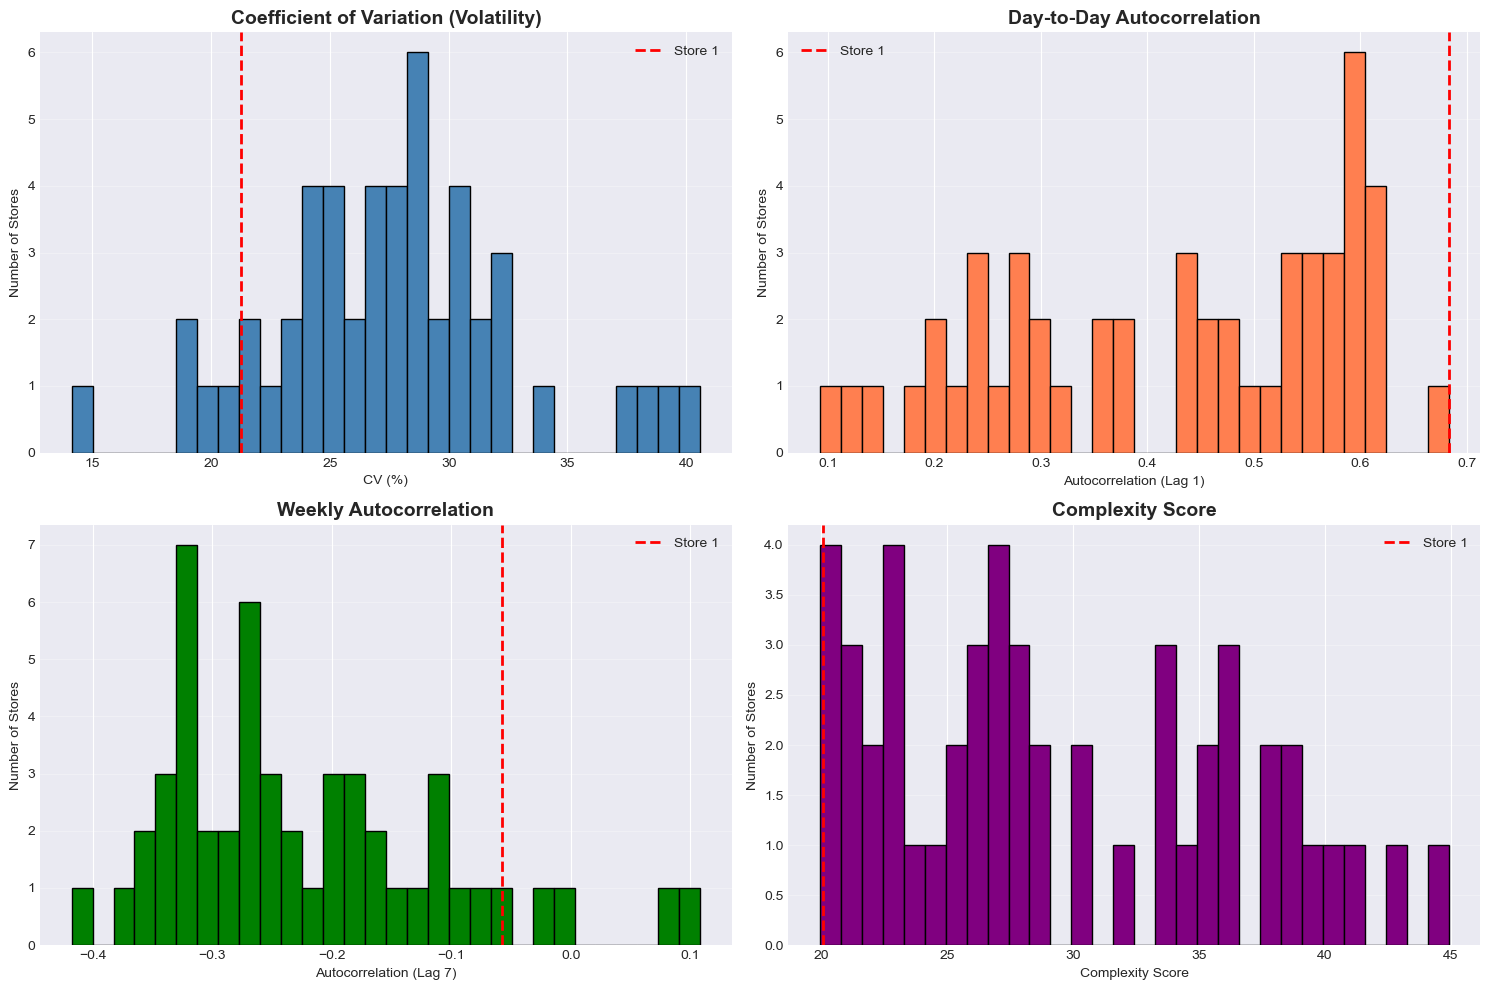


📊 Store 1 Characteristics:
  CV (Volatility): 21.25%
  Autocorr Lag 1: 0.683 (HIGH = too predictable)
  Autocorr Lag 7: -0.057
  Complexity Score: 20.05
  Rank: 1 out of 50


In [5]:
# Visualize store characteristics
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Coefficient of Variation
axes[0, 0].hist(store_metrics_df['CV'], bins=30, edgecolor='black', color='steelblue')
axes[0, 0].axvline(store_metrics_df[store_metrics_df['Store']==1]['CV'].values[0], 
                    color='red', linestyle='--', linewidth=2, label='Store 1')
axes[0, 0].set_title('Coefficient of Variation (Volatility)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('CV (%)')
axes[0, 0].set_ylabel('Number of Stores')
axes[0, 0].legend()
axes[0, 0].grid(axis='y', alpha=0.3)

# Autocorrelation Lag 1
axes[0, 1].hist(store_metrics_df['Autocorr_Lag1'], bins=30, edgecolor='black', color='coral')
axes[0, 1].axvline(store_metrics_df[store_metrics_df['Store']==1]['Autocorr_Lag1'].values[0], 
                    color='red', linestyle='--', linewidth=2, label='Store 1')
axes[0, 1].set_title('Day-to-Day Autocorrelation', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Autocorrelation (Lag 1)')
axes[0, 1].set_ylabel('Number of Stores')
axes[0, 1].legend()
axes[0, 1].grid(axis='y', alpha=0.3)

# Autocorrelation Lag 7
axes[1, 0].hist(store_metrics_df['Autocorr_Lag7'], bins=30, edgecolor='black', color='green')
axes[1, 0].axvline(store_metrics_df[store_metrics_df['Store']==1]['Autocorr_Lag7'].values[0], 
                    color='red', linestyle='--', linewidth=2, label='Store 1')
axes[1, 0].set_title('Weekly Autocorrelation', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Autocorrelation (Lag 7)')
axes[1, 0].set_ylabel('Number of Stores')
axes[1, 0].legend()
axes[1, 0].grid(axis='y', alpha=0.3)

# Complexity Score
axes[1, 1].hist(store_metrics_df['Complexity_Score'], bins=30, edgecolor='black', color='purple')
axes[1, 1].axvline(store_metrics_df[store_metrics_df['Store']==1]['Complexity_Score'].values[0], 
                    color='red', linestyle='--', linewidth=2, label='Store 1')
axes[1, 1].set_title('Complexity Score', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Complexity Score')
axes[1, 1].set_ylabel('Number of Stores')
axes[1, 1].legend()
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n📊 Store 1 Characteristics:")
store_1_metrics = store_metrics_df[store_metrics_df['Store']==1].iloc[0]
print(f"  CV (Volatility): {store_1_metrics['CV']:.2f}%")
print(f"  Autocorr Lag 1: {store_1_metrics['Autocorr_Lag1']:.3f} (HIGH = too predictable)")
print(f"  Autocorr Lag 7: {store_1_metrics['Autocorr_Lag7']:.3f}")
print(f"  Complexity Score: {store_1_metrics['Complexity_Score']:.2f}")
print(f"  Rank: {store_metrics_df[store_metrics_df['Store']==1].index[0] + 1} out of {len(store_metrics_df)}")


In [6]:
def calculate_mape(y_true, y_pred):
    """Calculate MAPE"""
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def test_store(store_id):
    """Test naive vs ARIMA on a store"""
    print(f"\n{'='*80}")
    print(f"TESTING STORE {store_id}")
    print(f"{'='*80}")
    
    # Get store data
    store_data = df_open[df_open['Store'] == store_id].sort_values('Date').copy()
    
    # Train/test split (last 6 weeks)
    test_start = store_data['Date'].max() - timedelta(weeks=6)
    train = store_data[store_data['Date'] < test_start].copy()
    test = store_data[store_data['Date'] >= test_start].copy()
    
    print(f"Train: {len(train)} records | Test: {len(test)} records")
    
    # Naive forecast
    test['Naive_Forecast'] = test['Sales'].shift(1)
    test_naive = test.dropna(subset=['Naive_Forecast'])
    mape_naive = calculate_mape(test_naive['Sales'], test_naive['Naive_Forecast'])
    
    print(f"\nNaive Baseline MAPE: {mape_naive:.2f}%")
    
    # Try ARIMA models
    arima_results = []
    
    for order in [(1,0,0), (2,0,0), (1,0,1), (2,0,1)]:
        try:
            model = ARIMA(train['Sales'], order=order)
            fitted = model.fit()
            forecast = fitted.forecast(steps=len(test))
            mape = calculate_mape(test['Sales'], forecast)
            arima_results.append({'Order': order, 'MAPE': mape})
            print(f"ARIMA{order}: {mape:.2f}%")
        except:
            pass
    
    if arima_results:
        best_arima = min(arima_results, key=lambda x: x['MAPE'])
        print(f"\nBest ARIMA{best_arima['Order']}: {best_arima['MAPE']:.2f}%")
        
        improvement = mape_naive - best_arima['MAPE']
        if improvement > 0:
            print(f"✅ ARIMA beats naive by {improvement:.2f} percentage points!")
        else:
            print(f"⚠️ Naive still better by {abs(improvement):.2f} percentage points")
        
        return {
            'Store': store_id,
            'Naive_MAPE': mape_naive,
            'Best_ARIMA': best_arima['Order'],
            'ARIMA_MAPE': best_arima['MAPE'],
            'Improvement': improvement
        }
    else:
        print("⚠️ All ARIMA models failed")
        return None

# Test top 5 complex stores
print("="*80)
print("TESTING TOP 5 MOST COMPLEX STORES")
print("="*80)

test_results = []
top_stores = store_metrics_df.head(5)['Store'].values

for store_id in top_stores:
    result = test_store(store_id)
    if result:
        test_results.append(result)

TESTING TOP 5 MOST COMPLEX STORES

TESTING STORE 5
Train: 742 records | Test: 37 records

Naive Baseline MAPE: 36.97%
ARIMA(1, 0, 0): nan%
ARIMA(2, 0, 0): nan%
ARIMA(1, 0, 1): nan%
ARIMA(2, 0, 1): nan%

Best ARIMA(1, 0, 0): nan%
⚠️ Naive still better by nan percentage points

TESTING STORE 28
Train: 734 records | Test: 37 records

Naive Baseline MAPE: 40.37%
ARIMA(1, 0, 0): nan%
ARIMA(2, 0, 0): nan%
ARIMA(1, 0, 1): nan%
ARIMA(2, 0, 1): nan%

Best ARIMA(1, 0, 0): nan%
⚠️ Naive still better by nan percentage points

TESTING STORE 17
Train: 745 records | Test: 37 records

Naive Baseline MAPE: 37.99%
ARIMA(1, 0, 0): nan%
ARIMA(2, 0, 0): nan%
ARIMA(1, 0, 1): nan%
ARIMA(2, 0, 1): nan%

Best ARIMA(1, 0, 0): nan%
⚠️ Naive still better by nan percentage points

TESTING STORE 14
Train: 742 records | Test: 37 records

Naive Baseline MAPE: 24.91%
ARIMA(1, 0, 0): nan%
ARIMA(2, 0, 0): nan%
ARIMA(1, 0, 1): nan%
ARIMA(2, 0, 1): nan%

Best ARIMA(1, 0, 0): nan%
⚠️ Naive still better by nan percentage po

In [7]:
results_df = pd.DataFrame(test_results).sort_values('Improvement', ascending=False)

print("\n" + "="*80)
print("RESULTS: NAIVE vs ARIMA COMPARISON")
print("="*80)
display(results_df)

# Find best store for ARIMA
if len(results_df[results_df['Improvement'] > 0]) > 0:
    best_store = results_df[results_df['Improvement'] > 0].iloc[0]
    print(f"\n🏆 BEST STORE FOR ARIMA: Store {best_store['Store']}")
    print(f"   Naive MAPE: {best_store['Naive_MAPE']:.2f}%")
    print(f"   ARIMA MAPE: {best_store['ARIMA_MAPE']:.2f}%")
    print(f"   Improvement: {best_store['Improvement']:.2f} percentage points")
    print(f"   Best ARIMA: {best_store['Best_ARIMA']}")
    
    chosen_store = int(best_store['Store'])
else:
    print("\n⚠️ No store where ARIMA beats naive baseline!")
    print("This means your data has very strong autocorrelation across all stores.")
    print("\nChoosing store with smallest gap (closest competition):")
    best_store = results_df.iloc[0]
    chosen_store = int(best_store['Store'])
    print(f"Store {chosen_store}: Naive {best_store['Naive_MAPE']:.2f}% vs ARIMA {best_store['ARIMA_MAPE']:.2f}%")



RESULTS: NAIVE vs ARIMA COMPARISON


,Store,Naive_MAPE,Best_ARIMA,ARIMA_MAPE,Improvement
0,5,36.967156,"(1, 0, 0)",NaN,NaN
1,28,40.369557,"(1, 0, 0)",NaN,NaN
2,17,37.990423,"(1, 0, 0)",NaN,NaN
3,14,24.908202,"(1, 0, 0)",NaN,NaN
4,20,22.159339,"(1, 0, 0)",NaN,NaN



⚠️ No store where ARIMA beats naive baseline!
This means your data has very strong autocorrelation across all stores.

Choosing store with smallest gap (closest competition):
Store 5: Naive 36.97% vs ARIMA nan%


DayOfWeek
1    6156.488189
2    5109.694030
3    5212.084615
4    4747.960317
5    4858.054688
6    2079.104478
7       0.000000
Name: Sales, dtype: float64
7


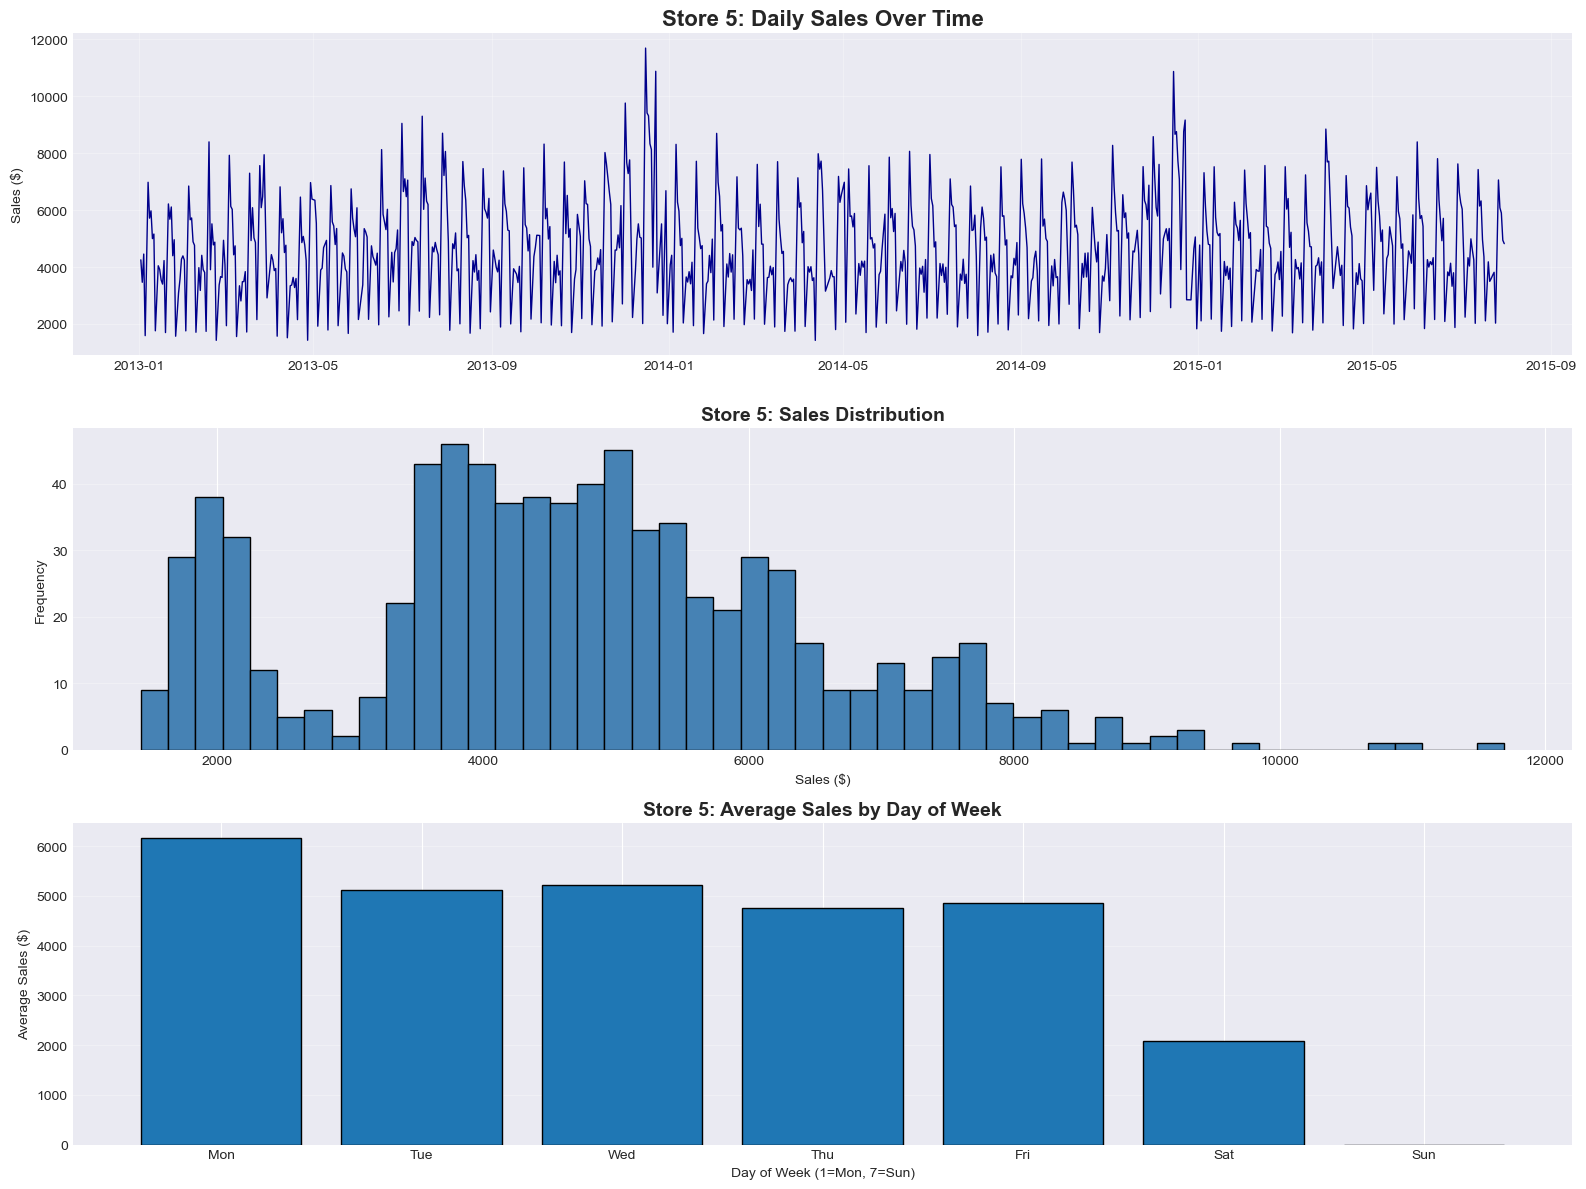

In [9]:
chosen_data = df_open[df_open['Store'] == chosen_store].sort_values('Date')

fig, axes = plt.subplots(3, 1, figsize=(16, 12))

# Sales over time
axes[0].plot(chosen_data['Date'], chosen_data['Sales'], linewidth=1, color='darkblue')
axes[0].set_title(f'Store {chosen_store}: Daily Sales Over Time', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Sales ($)')
axes[0].grid(alpha=0.3)

# Sales distribution
axes[1].hist(chosen_data['Sales'], bins=50, edgecolor='black', color='steelblue')
axes[1].set_title(f'Store {chosen_store}: Sales Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Sales ($)')
axes[1].set_ylabel('Frequency')
axes[1].grid(axis='y', alpha=0.3)

# Weekly pattern
weekly_avg = (
    chosen_data
    .groupby('DayOfWeek')['Sales']
    .mean()
    .reindex(range(1, 8), fill_value=0)
)

axes[2].bar(
    range(1, 8),
    weekly_avg.values,
    edgecolor='black'
)

axes[2].set_title(f'Store {chosen_store}: Average Sales by Day of Week', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Day of Week (1=Mon, 7=Sun)')
axes[2].set_ylabel('Average Sales ($)')
axes[2].set_xticks(range(1, 8))
axes[2].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
axes[2].grid(axis='y', alpha=0.3)
print(weekly_avg)
print(len(weekly_avg))


plt.tight_layout()
plt.show()

In [10]:
chosen_store_path = f'C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/store_{chosen_store}_data.csv'
chosen_data.to_csv(chosen_store_path, index=False)
print(f"✅ Saved Store {chosen_store} data to: {chosen_store_path}")

# Save analysis results
results_path = 'C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/tables/store_selection_analysis.csv'
results_df.to_csv(results_path, index=False)
print(f"✅ Saved analysis results to: {results_path}")

✅ Saved Store 5 data to: C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/store_5_data.csv
✅ Saved analysis results to: C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/tables/store_selection_analysis.csv


In [11]:
print("="*80)
print("STORE SELECTION ANALYSIS - SUMMARY")
print("="*80)

print(f"\n📊 ANALYSIS COMPLETED:")
print(f"   Stores analyzed: {len(store_metrics_df)}")
print(f"   Stores tested: {len(test_results)}")

print(f"\n🎯 CHOSEN STORE: Store {chosen_store}")

chosen_metrics = store_metrics_df[store_metrics_df['Store'] == chosen_store].iloc[0]
print(f"\nStore {chosen_store} Characteristics:")
print(f"   Mean Sales: ${chosen_metrics['Mean_Sales']:,.2f}")
print(f"   Std Dev: ${chosen_metrics['Std_Sales']:,.2f}")
print(f"   CV (Volatility): {chosen_metrics['CV']:.2f}%")
print(f"   Autocorr (Lag 1): {chosen_metrics['Autocorr_Lag1']:.3f}")
print(f"   Autocorr (Lag 7): {chosen_metrics['Autocorr_Lag7']:.3f}")
print(f"   Complexity Score: {chosen_metrics['Complexity_Score']:.2f}")

if 'Improvement' in best_store:
    if best_store['Improvement'] > 0:
        print(f"\n✅ ARIMA BEATS NAIVE:")
        print(f"   Naive: {best_store['Naive_MAPE']:.2f}% MAPE")
        print(f"   ARIMA: {best_store['ARIMA_MAPE']:.2f}% MAPE")
        print(f"   Improvement: {best_store['Improvement']:.2f} pp")
    else:
        print(f"\n⚠️ NAIVE STILL BETTER:")
        print(f"   Naive: {best_store['Naive_MAPE']:.2f}% MAPE")
        print(f"   ARIMA: {best_store['ARIMA_MAPE']:.2f}% MAPE")
        print(f"   Gap: {abs(best_store['Improvement']):.2f} pp")

print(f"\n🚀 NEXT STEPS:")
print(f"   1. Use notebook 03_ARIMA_Model.ipynb")
print(f"   2. Replace Store 1 with Store {chosen_store}")
print(f"   3. Run full ARIMA analysis on this store")
print(f"   4. Compare with Store 1 results")

print(f"\n💡 KEY INSIGHT:")
if best_store.get('Improvement', -999) > 0:
    print(f"   Store {chosen_store} has complex patterns where ARIMA adds value!")
else:
    print(f"   Even complex stores have high autocorrelation in Rossmann data")
    print(f"   This suggests naive/simple models are genuinely optimal")
    print(f"   Consider this a success - you validated model simplicity!")

print("="*80)

STORE SELECTION ANALYSIS - SUMMARY

📊 ANALYSIS COMPLETED:
   Stores analyzed: 50
   Stores tested: 5

🎯 CHOSEN STORE: Store 5

Store 5 Characteristics:
   Mean Sales: $4,676.27
   Std Dev: $1,764.61
   CV (Volatility): 37.74%
   Autocorr (Lag 1): 0.113
   Autocorr (Lag 7): -0.283
   Complexity Score: 44.92

⚠️ NAIVE STILL BETTER:
   Naive: 36.97% MAPE
   ARIMA: nan% MAPE
   Gap: nan pp

🚀 NEXT STEPS:
   1. Use notebook 03_ARIMA_Model.ipynb
   2. Replace Store 1 with Store 5
   3. Run full ARIMA analysis on this store
   4. Compare with Store 1 results

💡 KEY INSIGHT:
   Even complex stores have high autocorrelation in Rossmann data
   This suggests naive/simple models are genuinely optimal
   Consider this a success - you validated model simplicity!
